In [ ]:
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os, sys
if Path.cwd().name == 'analysis':
    os.chdir('..')
sys.path.insert(0, os.getcwd())


SEASON_CD = {'winter': 1, 'spring': 2, 'summer': 3, 'fall': 4}
CUT_T = 2019 * 4 + 2  # spring 2019


In [4]:
panel = pd.read_csv('data/customer_panel.csv')
propensities = pd.read_csv('data/customer_propensities.csv')
aggregate = pd.read_csv('data/aggregate.csv')


# Lorehaven Pricing Evaluation — Part 1: EDA and Analysis Design

## Context

>Lorehaven initially charged $15. Promotions were available in five regions from the start of the observed panel. Those regions reduced the base price to $12 in spring 2019; Panem retained $15 and did not offer promotions. Eligibility follows business rules; discount depth is randomized among eligible customers.

## Business Questions

1. **Did the 2019 base-price reduction improve outcomes?**
   - Decision: retain $12 or reconsider the base price.
   - Evidence: changes in cut regions relative to Panem, subject to comparable counterfactual trends.
   - Primary metric: revenue per observed panel customer.
   - Secondary metrics: active members

2. **Does the promotion program improve revenue compared with no promotions?**
   - Decision: continue, modify, or test the program.
   - Evidence: $0 off arm if available / extrapolate
   - Primary metric: short-term revenue per observed panel customer.

3. **Which tested discount depth performs best among eligible customers?**
   - Decision: choose acquisition and renewal discounts under existing eligibility rules.
   - Evidence: randomized assignments
   - Primary metric: short-term revenue per offer, including non-converters and churners.

Revenue is `sign_up_flag × membership_price`


## 1. Validate Files and Joins

In [6]:
# Validate keys and create one consistent seasonal index.
panel['season_cd'] = panel['season'].map(SEASON_CD)
assert panel['season_cd'].notna().all(), 'Unexpected season labels'
panel['t'] = panel['year'] * 4 + panel['season_cd']
panel['year_season'] = panel['year'].astype(str) + '_' + panel['season_cd'].astype(str)
assert not panel.duplicated(['customer_id', 'year', 'season']).any(), 'Duplicate customer-periods'
assert not aggregate.duplicated(['region_name', 'year', 'season']).any(), 'Duplicate aggregate keys'
assert panel[['sign_up_flag', 'discount_flag']].isin([0, 1]).all().all(), 'Invalid flags'
assert panel['membership_price'].notna().all() and panel['membership_price'].ge(0).all()
region_change = panel.groupby('customer_id')['region_name'].nunique().gt(1).sum()
assert region_change == 0, 'Review region changes'

# Assume summer scores apply from that summer through the following spring.
assert set(propensities['season'].unique()) == {'summer'}, 'Review score refresh timing'
panel['score_year'] = panel['year'].where(panel['season_cd'].ge(3), panel['year'] - 1)
scores = propensities.drop(columns='season').rename(columns={'year': 'score_year'})
panel_prop = panel.merge(scores, how='left',
    on=['customer_id', 'score_year', 'region_id', 'region_name'], validate='many_to_one')
assert len(panel_prop) == len(panel)
score_cols = ['customer_tv_score', 'customer_radio_score', 'customer_social_score',
              'customer_podcast_score', 'customer_display_score']
print('Periods with any missing propensity score:')
display(panel_prop.loc[panel_prop[score_cols].isna().any(axis=1)]
        .groupby(['year', 'season']).size().rename('rows').reset_index())

panel_prop = panel_prop.sort_values(['customer_id', 't']).reset_index(drop=True)
g = panel_prop.groupby('customer_id', sort=False)
panel_prop['prev_member'] = g['sign_up_flag'].shift(1)
panel_prop['ever_member_before'] = g['sign_up_flag'].cummax().groupby(panel_prop['customer_id']).shift(1)
panel_prop['at_risk_acq'] = panel_prop['prev_member'].eq(0)
panel_prop['at_risk_ret'] = panel_prop['prev_member'].eq(1)
panel_prop['join_event'] = panel_prop['at_risk_acq'] & panel_prop['sign_up_flag'].eq(1)
panel_prop['rejoin'] = panel_prop['join_event'] & panel_prop['ever_member_before'].eq(1)
panel_prop['first_observed_join'] = panel_prop['join_event'] & panel_prop['ever_member_before'].eq(0)
panel_prop['churn'] = panel_prop['at_risk_ret'] & panel_prop['sign_up_flag'].eq(0)
panel_prop['promo_region'] = panel_prop['region_name'].ne('panem')
panel_prop['region_group'] = np.where(panel_prop['promo_region'], 'Other regions', 'Panem')
panel_prop['post_cut'] = panel_prop['t'].ge(CUT_T)
panel_prop['base_price'] = np.where(panel_prop['promo_region'] & panel_prop['post_cut'], 12, 15)
panel_prop['depth'] = panel_prop['base_price'] - panel_prop['membership_price']
panel_prop['revenue'] = panel_prop['sign_up_flag'] * panel_prop['membership_price']


Periods with any missing propensity score:


,year,season,rows
0,2017,spring,510089
1,2017,winter,510089


## 2. Panel Coverage

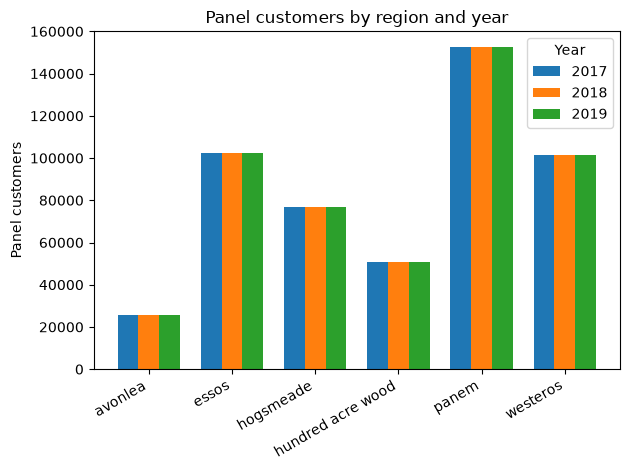

In [7]:
customers = panel_prop.groupby(['region_name', 'year']).agg(total_customers = ('customer_id', 'nunique')).reset_index()

regions = customers['region_name'].unique()
x = np.arange(len(regions))
width = 0.25

for i, (year, group) in enumerate(customers.groupby('year')):
    plt.bar(x + (i - 1) * width, group['total_customers'], width, label=year)

plt.xticks(x, regions, rotation=30, ha='right')
plt.ylabel('Panel customers')
plt.title('Panel customers by region and year')
plt.legend(title='Year')
plt.tight_layout()
plt.show()


In [9]:
# Examine panel entry, disappearance, and gaps in observation
n_periods = len(panel_prop[['year', 'season']].drop_duplicates())
print(f"{n_periods} year x season observations in the panel")

periods_per_customer = panel_prop.groupby('customer_id').size()

if (periods_per_customer == n_periods).all():
    print(f"[INFO] all customers are observed in all {n_periods} periods")
else:
    n_missing = (periods_per_customer != n_periods).sum()
    print(f"[INFO] {n_missing} customers are not observed in all {n_periods} periods")

# Count customers who never become members
ever_member = panel_prop.groupby('customer_id')['sign_up_flag'].max()

# Verify converage of panel data
member_by_season = panel_prop.groupby(['year', 'season','region_name']).agg(total_member = ('sign_up_flag', 'sum'))
panel_agg = pd.merge(aggregate[['year', 'season', 'member_count', 'region_name']], 
                     member_by_season, 
                     on = ['year', 'season','region_name'], 
                     how='left')

print(f"[INFO] mismatch member count with Aggregate: {len(panel_agg[panel_agg['member_count'] != panel_agg['total_member']])}")

n_never = (ever_member == 0).sum()
print(f"[INFO] {n_never} customers never became members ({n_never / len(ever_member):.1%} of customers)")




12 year x season observations in the panel
[INFO] all customers are observed in all 12 periods
[INFO] mismatch member count with Aggregate: 0
[INFO] 298316 customers never became members (58.5% of customers)


**Summary.** All 510,089 customers are observed in all 12 periods; 298,316 (58.5%) never become members during the window. Panel member counts match the aggregate table. This supports consistency between files, but does not establish that every potential prospect in the market is represented.

The fixed panel supplies the revenue-per-customer denominator. Its size is a coverage check, not business growth. Acquisition risk sets change as customers join, cancel, and rejoin.

In [10]:
# Reconcile customer-level totals with aggregate records.
keys = ['region_name', 'year', 'season']
totals = panel_prop.groupby(keys).agg(
    panel_members=('sign_up_flag', 'sum'), panel_social=('social_ad_impressions', 'sum'),
    panel_podcast=('podcast_ad_listen', 'sum'), panel_search=('search_flag', 'sum')).reset_index()
reconciled = aggregate.merge(totals, on=keys, how='outer', validate='one_to_one', indicator=True)
assert reconciled['_merge'].eq('both').all(), 'Region-period coverage differs'
pairs = {'members': ('member_count', 'panel_members'), 'social': ('social_impressions', 'panel_social'),
         'podcast': ('podcast_ad_listens', 'panel_podcast'), 'search': ('search_impressions', 'panel_search')}
display(pd.Series({name: np.isclose(reconciled[a], reconciled[b]).mean()
                   for name, (a, b) in pairs.items()}, name='Share of matching region-periods'))


members    1.0
social     1.0
podcast    1.0
search     1.0
Name: Share of matching region-periods, dtype: float64

## 3. Membership Trend Over Time

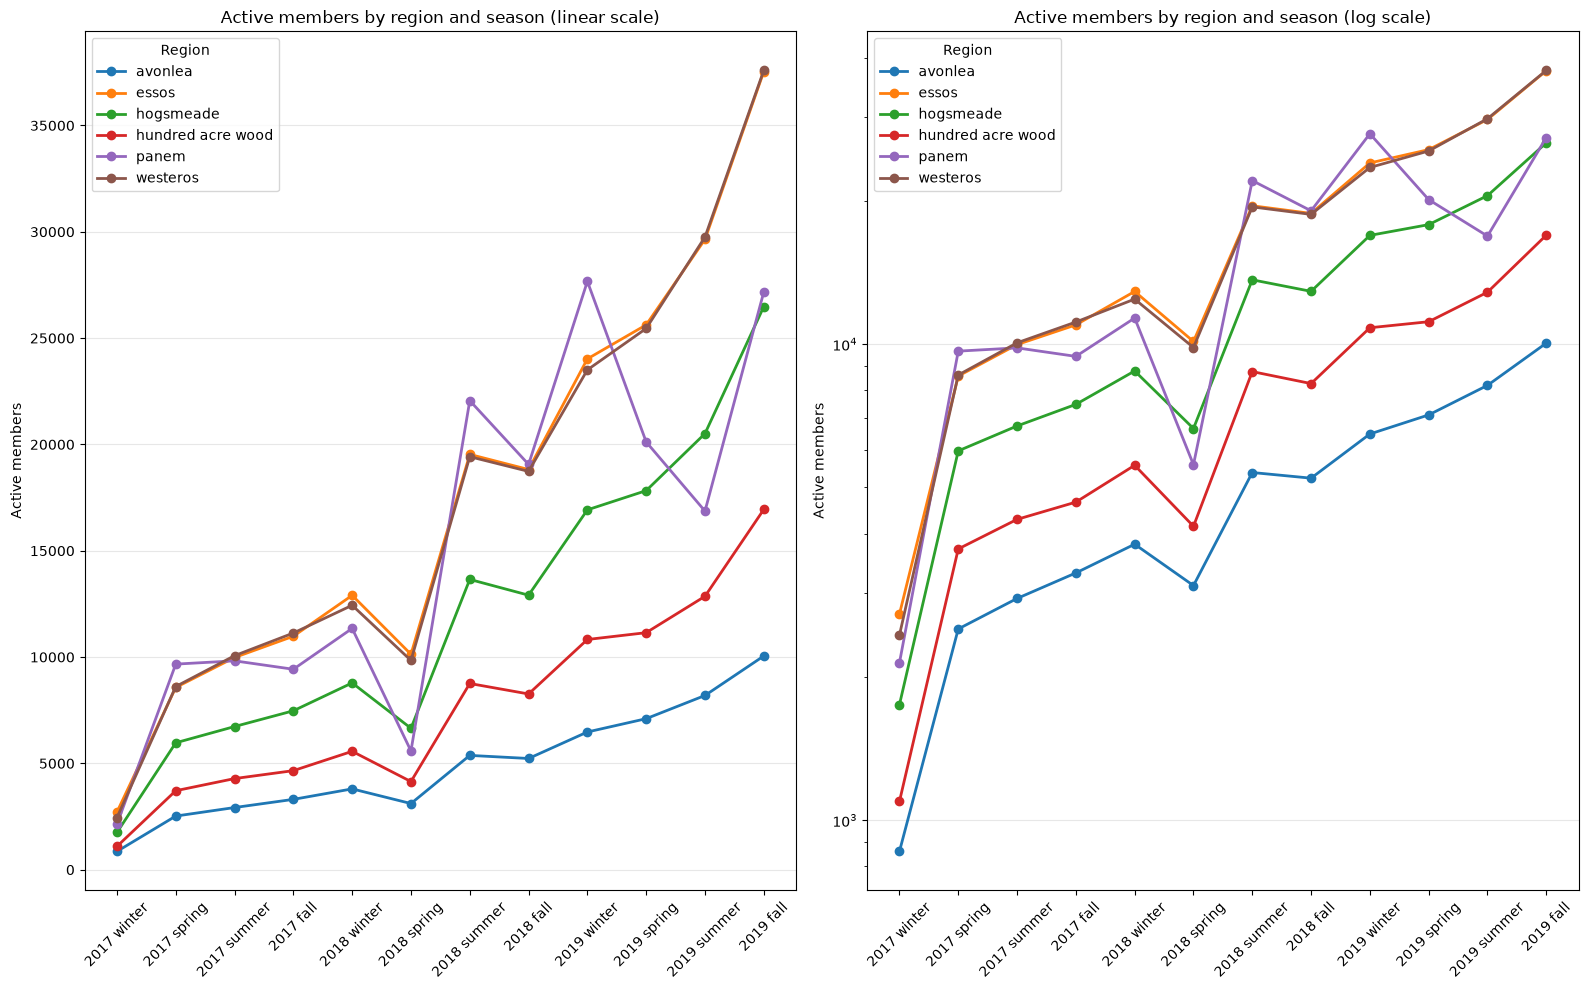

In [12]:
# active memeber trend
active_member_season_region = panel_prop.groupby(['year', 'season', 'region_name', 'season_cd']).agg(active_members = ('sign_up_flag', 'sum')).reset_index()

plot_df = active_member_season_region.copy()
plot_df = plot_df.sort_values(['year', 'season_cd'])
plot_df['period'] = plot_df['year'].astype(str) + ' ' + plot_df['season']

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

for ax, scale in zip(axes, ['linear', 'log']):
    for region, group in plot_df.groupby('region_name'):
        ax.plot(group['period'], group['active_members'], marker='o', linewidth=2, label=region)

    ax.set_yscale(scale)
    ax.set_ylabel('Active members')
    ax.set_title(f'Active members by region and season ({scale} scale)')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Region')

plt.tight_layout()
plt.show()


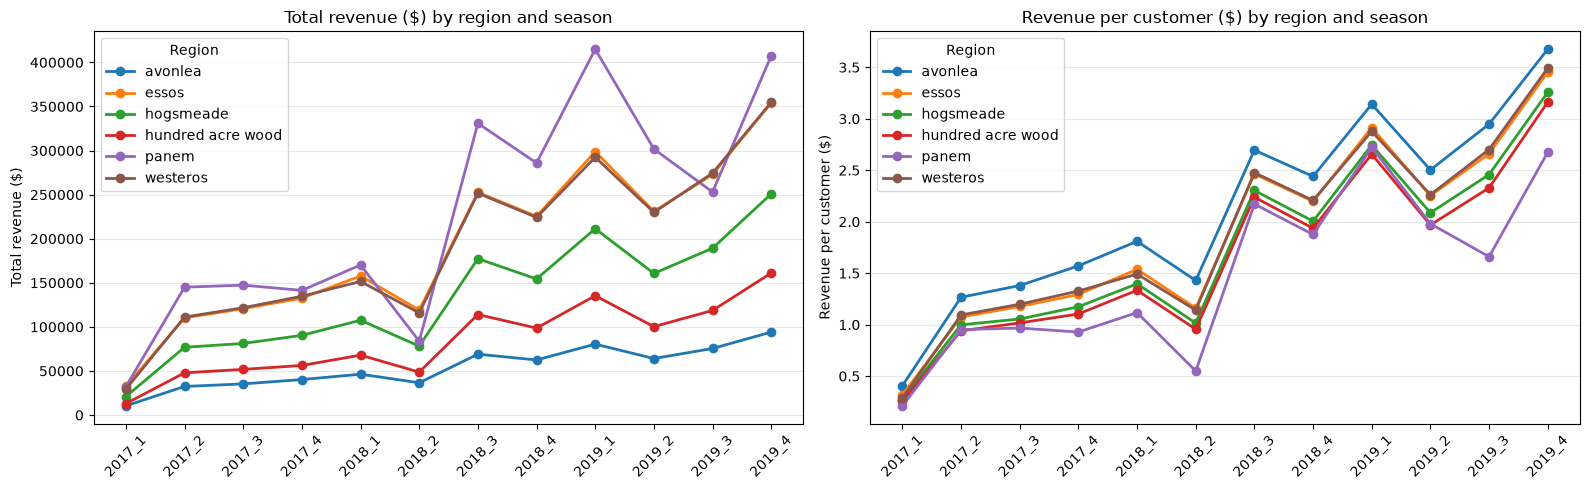

In [13]:
revenue_df = panel_prop.assign(revenue=panel_prop['sign_up_flag'] * panel_prop['membership_price'])

revenue_region = (revenue_df
                  .groupby(['year_season', 'region_name'])
                  .agg(total_revenue=('revenue', 'sum'),
                       revenue_per_customer=('revenue', 'mean'))
                  .reset_index())

metrics = [('total_revenue', 'Total revenue ($)'),
           ('revenue_per_customer', 'Revenue per customer ($)')]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (metric, label) in zip(axes, metrics):
    for region, group in revenue_region.groupby('region_name'):
        ax.plot(group['year_season'], group[metric], marker='o', linewidth=2, label=region)

    ax.set_ylabel(label)
    ax.set_title(f'{label} by region and season')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Region')

plt.tight_layout()
plt.show()


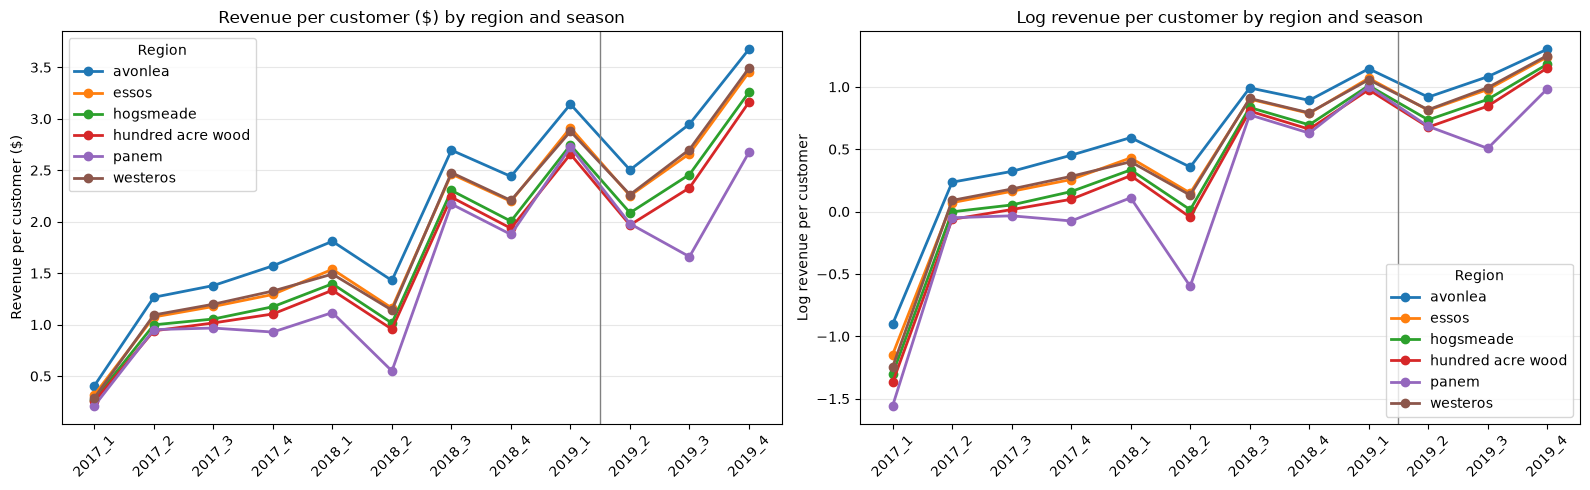

In [14]:
revenue_region['log_revenue_per_customer'] = np.log(revenue_region['revenue_per_customer'])

pc_metrics = [('revenue_per_customer', 'Revenue per customer ($)'),
              ('log_revenue_per_customer', 'Log revenue per customer')]

# Seasons are plotted at x = 0, 1, 2, ...; put the cut line halfway between 2019_1 and 2019_2
seasons = sorted(revenue_region['year_season'].unique())
cut_x = seasons.index('2019_2') - 0.5

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (metric, label) in zip(axes, pc_metrics):
    for region, group in revenue_region.groupby('region_name'):
        ax.plot(group['year_season'], group[metric], marker='o', linewidth=2, label=region)

    ax.axvline(cut_x, color='gray', linewidth=1)
    ax.set_ylabel(label)
    ax.set_title(f'{label} by region and season')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Region')

plt.tight_layout()
plt.show()


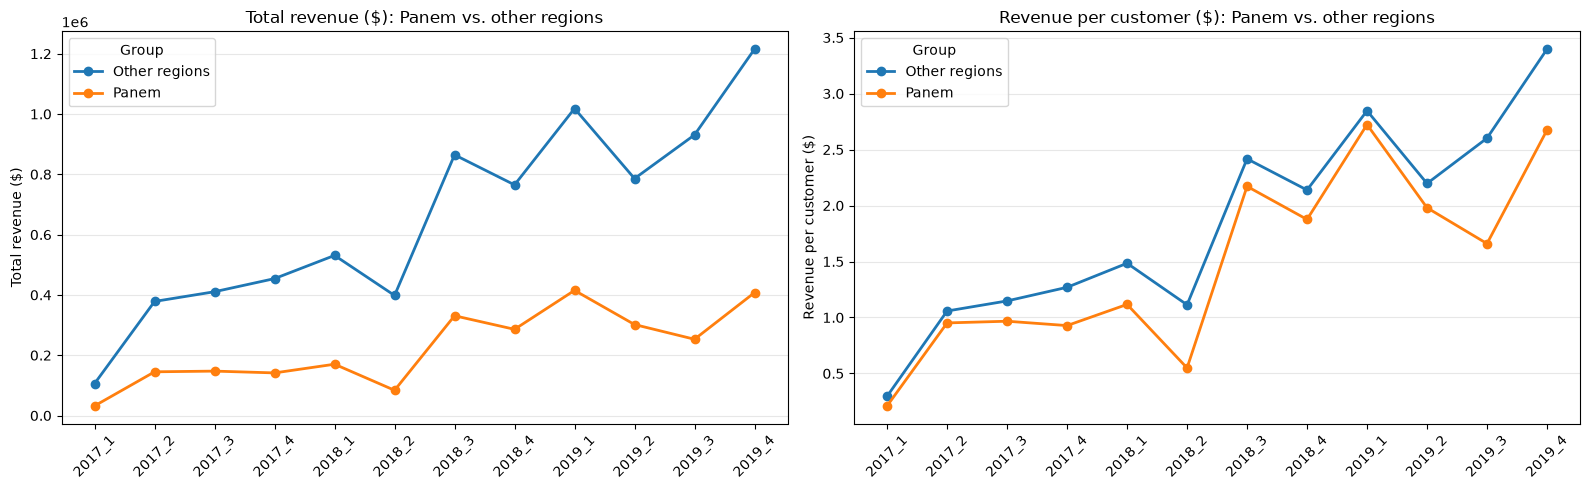

In [15]:
revenue_df['group'] = revenue_df['region_name'].map(lambda r: 'Panem' if r == 'panem' else 'Other regions')

revenue_group = (revenue_df
                 .groupby(['year_season', 'group'])
                 .agg(total_revenue=('revenue', 'sum'),
                      revenue_per_customer=('revenue', 'mean'))
                 .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (metric, label) in zip(axes, metrics):
    for group_name, group in revenue_group.groupby('group'):
        ax.plot(group['year_season'], group[metric], marker='o', linewidth=2, label=group_name)

    ax.set_ylabel(label)
    ax.set_title(f'{label}: Panem vs. other regions')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Group')

plt.tight_layout()
plt.show()


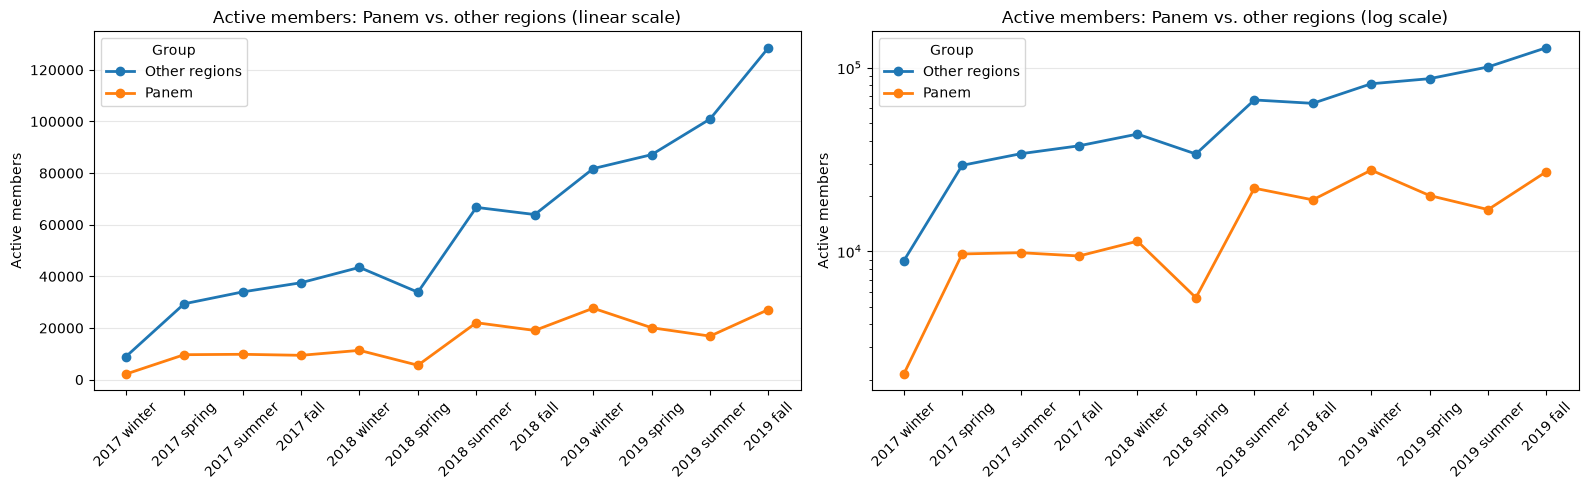

In [16]:
plot_df['group'] = plot_df['region_name'].map(lambda r: 'Panem' if r == 'panem' else 'Other regions')

pooled = (plot_df
          .groupby(['year', 'season_cd', 'period', 'group'])
          .agg(active_members=('active_members', 'sum'))
          .reset_index()
          .sort_values(['year', 'season_cd']))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, scale in zip(axes, ['linear', 'log']):
    for group_name, group in pooled.groupby('group'):
        ax.plot(group['period'], group['active_members'], marker='o', linewidth=2, label=group_name)

    ax.set_yscale(scale)
    ax.set_ylabel('Active members')
    ax.set_title(f'Active members: Panem vs. other regions ({scale} scale)')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Group')

plt.tight_layout()
plt.show()


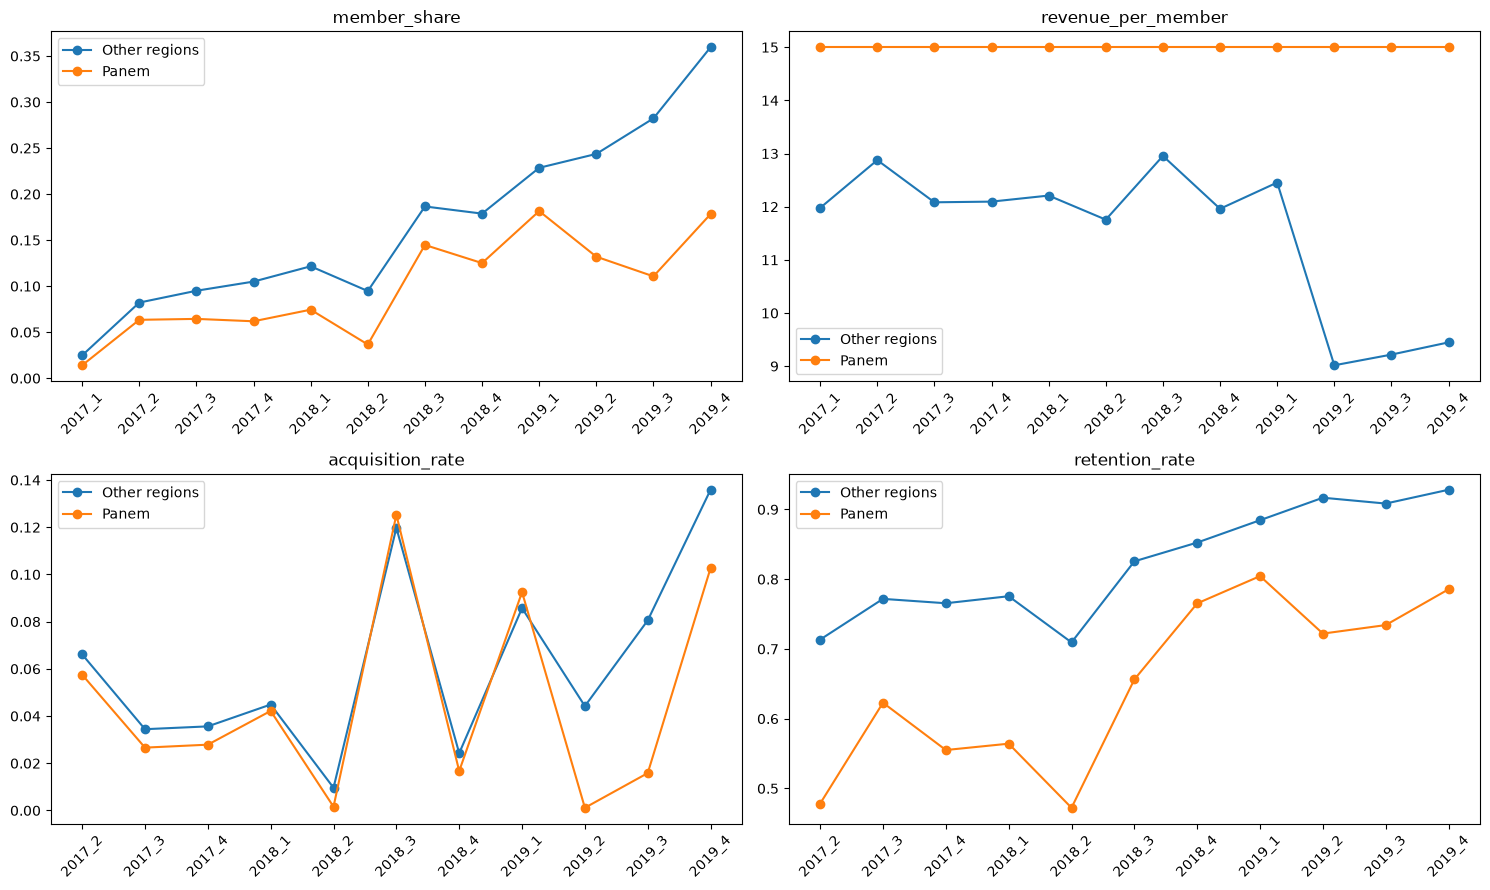

In [17]:
# Revenue decomposition and transition rates.
keys = ['year_season', 'region_group']
trends = panel_prop.groupby(keys).agg(
    member_share=('sign_up_flag', 'mean'), revenue_per_customer=('revenue', 'mean'))
trends['revenue_per_member'] = panel_prop.loc[panel_prop['sign_up_flag'].eq(1)].groupby(keys)['membership_price'].mean()
trends['acquisition_rate'] = panel_prop.loc[panel_prop['at_risk_acq']].groupby(keys)['sign_up_flag'].mean()
trends['retention_rate'] = panel_prop.loc[panel_prop['at_risk_ret']].groupby(keys)['sign_up_flag'].mean()
assert np.allclose(trends['revenue_per_customer'], trends['member_share'] * trends['revenue_per_member'].fillna(0))
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, metric in zip(axes.flat, ['member_share', 'revenue_per_member', 'acquisition_rate', 'retention_rate']):
    wide = trends[metric].unstack()
    for name in wide:
        ax.plot(wide.index, wide[name], marker='o', label=name)
    ax.set_title(metric)
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()


**Summary.** The existing results show that the retention advantage over Panem narrows before the cut, while acquisition gaps vary strongly by season. Panem's acquisition pattern also shifts from summer toward fall in 2019. These patterns make Panem questionable as counterfactual.

## 4. Marketing Reach Trend

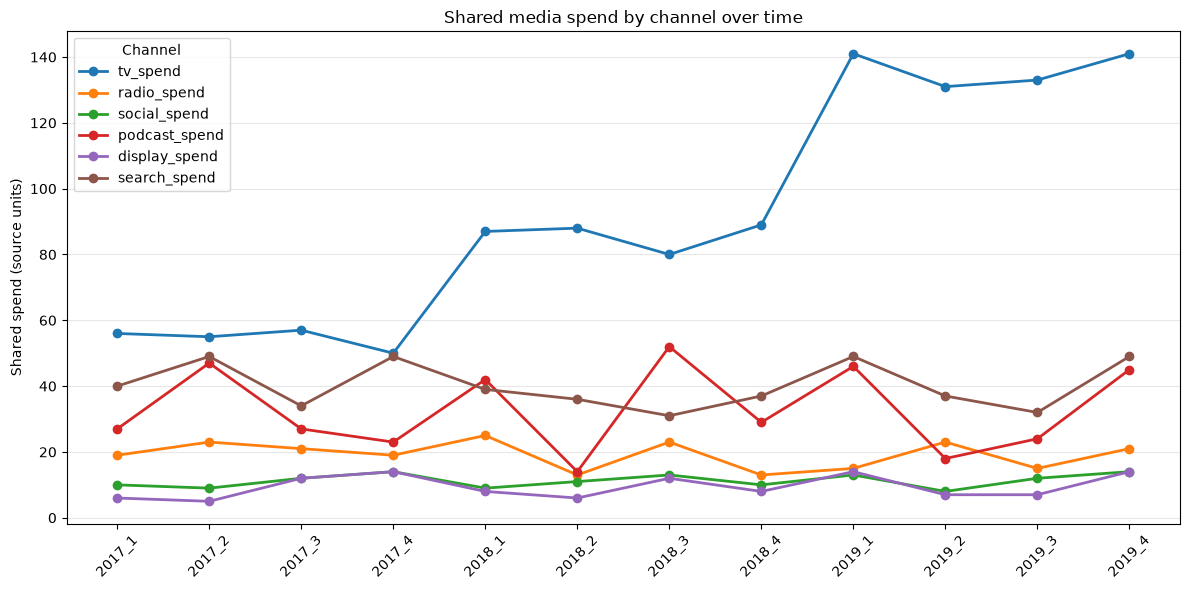

In [18]:
media = aggregate.copy()
season_cd = media['season'].map({'winter': 1, 'spring': 2, 'summer': 3, 'fall': 4})
media['year_season'] = media['year'].astype(str) + '_' + season_cd.astype(str)

spend_cols = ['tv_spend', 'radio_spend', 'social_spend', 'podcast_spend', 'display_spend', 'search_spend']

# The brief defines spend as universal; retain one shared value per period.
assert media.groupby('year_season')[spend_cols].nunique().le(1).all().all()
spend = media.groupby('year_season')[spend_cols].mean().sort_index()

fig, ax = plt.subplots(figsize=(12, 6))
for col in spend_cols:
    ax.plot(spend.index, spend[col], marker='o', linewidth=2, label=col)

ax.set_ylabel('Shared spend (source units)')
ax.set_title('Shared media spend by channel over time')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Channel')
plt.tight_layout()
plt.show()


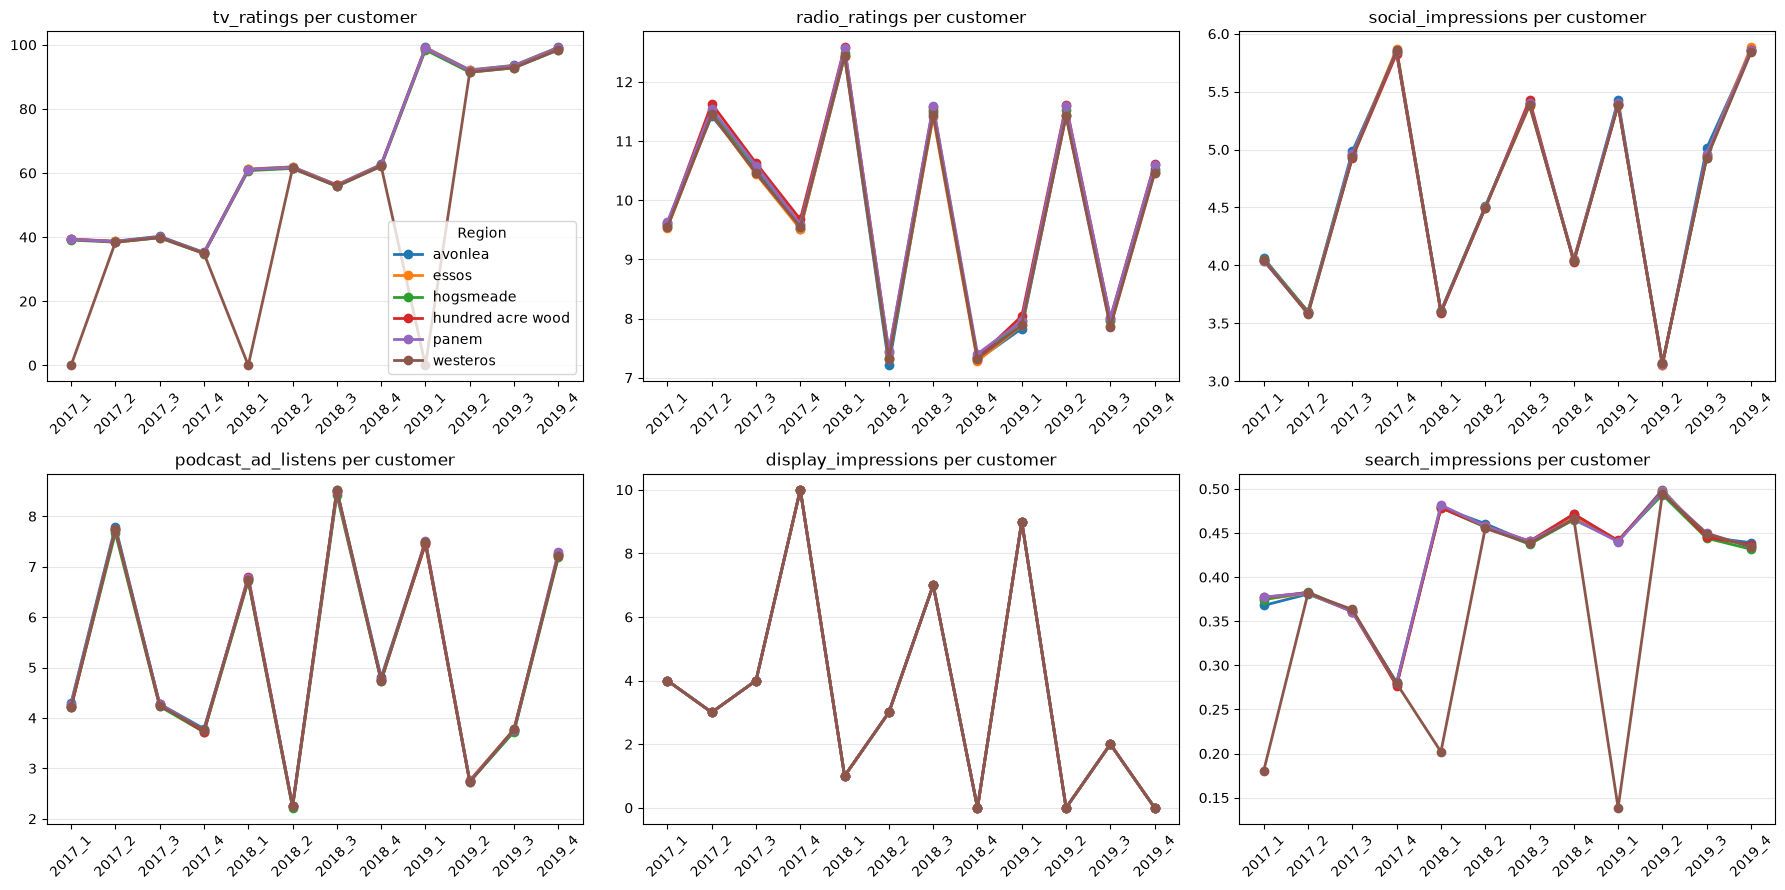

In [19]:
media = aggregate.copy()
season_cd = media['season'].map({'winter': 1, 'spring': 2, 'summer': 3, 'fall': 4})
media['year_season'] = media['year'].astype(str) + '_' + season_cd.astype(str)
media = media.sort_values('year_season')

exposure_cols = ['tv_ratings', 'radio_ratings', 'social_impressions',
                 'podcast_ad_listens', 'display_impressions', 'search_impressions']

# Exposure per customer, so big regions don't dominate
region_size = panel_prop.groupby('region_name')['customer_id'].nunique()
media[exposure_cols] = media[exposure_cols].div(media['region_name'].map(region_size), axis=0)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, exposure_cols):
    for region, group in media.groupby('region_name'):
        ax.plot(group['year_season'], group[col], marker='o', linewidth=2, label=region)
    ax.set_title(f'{col} per customer')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
axes.flat[0].legend(title='Region')
plt.tight_layout()
plt.show()


**Summary.** Spend is universal. Westeros records zero TV ratings each winter. Display impressions are zero across regions in fall 2018, spring 2019, and fall 2019 despite positive spend.

## 5. Price Policy

In [20]:
panel_prop[(panel_prop['membership_price'] == 12) & (panel_prop['discount_flag']==0)].groupby('region_name').agg(first_cut = ('year_season', 'min'))

,first_cut
region_name,
avonlea,2019_2
essos,2019_2
hogsmeade,2019_2
hundred acre wood,2019_2
westeros,2019_2


In [21]:
panel_prop[panel_prop['discount_flag']==1].groupby('region_name').agg(first_promo = ('year_season', 'min'))

,first_promo
region_name,
avonlea,2017_1
essos,2017_1
hogsmeade,2017_1
hundred acre wood,2017_1
westeros,2017_1


**Summary.** Five regions reduced the base price in spring 2019; Panem did not. Promotions were already observed in those five regions in winter 2017, the first observed season. Q1 concerns this menu shift within an existing promotion program. Q2 has no observed pre-promotion period. There are only three post-cut seasons

In [22]:
# Verify the price menu used to construct depth.
display(panel_prop.assign(window=np.where(panel_prop['post_cut'], 'post-cut', 'pre-cut'))
        .groupby(['region_group', 'window', 'discount_flag'])['membership_price'].agg(['min', 'max', 'nunique']))
assert panel_prop.loc[panel_prop['discount_flag'].eq(0), 'depth'].eq(0).all()
assert panel_prop.loc[panel_prop['discount_flag'].eq(1), 'depth'].isin([1, 2, 3, 4, 5]).all()


min  max  nunique
region_group  window   discount_flag                   
Other regions post-cut 0               12   12        1
                       1                7   11        5
              pre-cut  0               15   15        1
                       1               10   14        5
Panem         post-cut 0               15   15        1
              pre-cut  0               15   15        1

**Promotion eligibility.** Separate offers to prior-period non-members from renewal offers to prior-period members. Include customers who cancel. Approximately 25% of prospects receive an offer each season, compared with 100% of renewal decisions.

In [23]:
promo = panel_prop.loc[panel_prop['promo_region']]
offer_rates = pd.DataFrame({
    'Prospects': promo.loc[promo['at_risk_acq']].groupby('year_season')['discount_flag'].mean(),
    'Renewal decisions': promo.loc[promo['at_risk_ret']].groupby('year_season')['discount_flag'].mean(),
    'Churners': promo.loc[promo['churn']].groupby('year_season')['discount_flag'].mean()})
display(offer_rates.round(3))


,Prospects,Renewal decisions,Churners
year_season,,,
2017_2,0.250,1.0,1.0
2017_3,0.249,1.0,1.0
2017_4,0.251,1.0,1.0
2018_1,0.251,1.0,1.0
2018_2,0.251,1.0,1.0
2018_3,0.250,1.0,1.0
2018_4,0.249,1.0,1.0
2019_1,0.250,1.0,1.0
2019_2,0.249,1.0,1.0


### Cancellation and Rejoining

In [24]:
# Full-panel lags include cancellations in Panem.
flows = panel_prop.groupby(['year_season', 'region_group']).agg(
    members=('sign_up_flag', 'sum'), first_observed_joins=('first_observed_join', 'sum'),
    rejoins=('rejoin', 'sum'), cancellations=('churn', 'sum'))
previous_members = flows.groupby(level='region_group')['members'].shift(1)
expected = previous_members + flows['first_observed_joins'] + flows['rejoins'] - flows['cancellations']
assert expected[previous_members.notna()].eq(flows.loc[previous_members.notna(), 'members']).all()
display(flows)
print(f"Cancellation events: {panel_prop['churn'].sum():,}")
print(f"Rejoining events: {panel_prop['rejoin'].sum():,}")


members  first_observed_joins  rejoins  \
year_season region_group                                            
2017_1      Other regions     8862                     0        0   
            Panem             2141                     0        0   
2017_2      Other regions    29388                 23066        0   
            Panem             9668                  8644        0   
2017_3      Other regions    33984                 11110      193   
            Panem             9822                  3713       87   
2017_4      Other regions    37546                 10819      712   
            Panem             9426                  3656      318   
2018_1      Other regions    43488                 12633     1735   
            Panem            11347                  5093      936   
2018_2      Other regions    33874                  2528      496   
            Panem             5583                   165       59   
2018_3      Other regions    66737                 28717    10054   
            Panem            22060                 13210     5186   
2018_4      Other regions    63956                  5052     2009   
            Panem            19060                  1488      689   
2019_1      Other regions    81754                 16039     9142   
            Panem            27669                  7601     4736   
2019_2      Other regions    87153                  8559     3642   
            Panem            20118                    68       73   
2019_3      Other regions   100959                 13215     8572   
            Panem            16865                   954     1140   
2019_4      Other regions   128602                 18523    16365   
            Panem            27169                  5917     8004   

                           cancellations  
year_season region_group                  
2017_1      Other regions              0  
            Panem                      0  
2017_2      Other regions           2540  
            Panem                   1117  
2017_3      Other regions           6707  
            Panem                   3646  
2017_4      Other regions           7969  
            Panem                   4370  
2018_1      Other regions           8426  
            Panem                   4108  
2018_2      Other regions          12638  
            Panem                   5988  
2018_3      Other regions           5908  
            Panem                   1919  
2018_4      Other regions           9842  
            Panem                   5177  
2019_1      Other regions           7383  
            Panem                   3728  
2019_2      Other regions           6802  
            Panem                   7692  
2019_3      Other regions           7981  
            Panem                   5347  
2019_4      Other regions           7245  
            Panem                   3617

Cancellation events: 130,150
Rejoining events: 74,148


## 6. Audit the Randomized Discount Design

In [25]:
pre_offers = panel_prop.loc[~panel_prop['post_cut'] & panel_prop['discount_flag'].eq(1)]
print(f"Pre-cut zero-discount offers: {pre_offers['depth'].eq(0).sum():,}")
display(pre_offers.groupby(['membership_price', 'depth']).size().rename('offers').reset_index())


Pre-cut zero-discount offers: 0


,membership_price,depth,offers
0,10,5,209088
1,11,4,208634
2,12,3,208951
3,13,2,208670
4,14,1,208568


In [26]:
# The post-cut full price in promotion regions is $12.
post_offers = panel_prop.loc[panel_prop['post_cut'] & panel_prop['discount_flag'].eq(1)]
print(f"Post-cut zero-discount offers: {post_offers['depth'].eq(0).sum():,}")
display(post_offers.groupby(['membership_price', 'depth']).size().rename('offers').reset_index())


Post-cut zero-discount offers: 0


,membership_price,depth,offers
0,7,5,94377
1,8,4,94109
2,9,3,94245
3,10,2,94151
4,11,1,93792


In [28]:
panel_prop[panel_prop['discount_flag'].eq(1)].groupby('customer_id').size()

customer_id
0         6
1         9
2         3
4         4
5         4
         ..
510080    4
510084    4
510085    7
510086    2
510087    6
Length: 349814, dtype: int64

**Summary.** Discounts range from $1 to $5 off the prevailing base price, with no randomized $0 arm. The randomized comparison identifies relative performance among tested depths, not the effect of promotions versus none.

Depth can change during a membership spell. The assignment unit is a customer-period.

In [29]:
# Assignment balance includes non-converters and churners.
decisions = panel_prop.loc[
    panel_prop['promo_region'] & panel_prop['discount_flag'].eq(1)
    & (panel_prop['at_risk_acq'] | panel_prop['at_risk_ret'])].copy()
decisions['decision'] = np.where(decisions['at_risk_ret'], 'renewal', 'acquisition')
decisions['window'] = np.where(decisions['post_cut'], 'post-cut', 'pre-cut')
display(pd.crosstab([decisions['decision'], decisions['window']], decisions['depth'], normalize='index').round(3))
display(pd.crosstab(decisions['region_name'], decisions['depth'], normalize='index').round(3))

# Balance on lagged membership history and available external scores.
# Same-summer score availability before assignment is a timing assumption.
decisions['previously_a_member'] = decisions['ever_member_before'].astype(float)
balance_cols = ['previously_a_member'] + score_cols
display(decisions.groupby(['decision', 'window', 'depth'])[balance_cols].mean().round(3))
display(decisions.groupby(['decision', 'window', 'depth'])[score_cols].count())


depth                     1      2      3      4      5
decision    window                                     
acquisition post-cut  0.199  0.200  0.201  0.201  0.199
            pre-cut   0.199  0.200  0.201  0.199  0.200
renewal     post-cut  0.200  0.200  0.200  0.199  0.201
            pre-cut   0.200  0.199  0.199  0.201  0.201

depth,1,2,3,4,5
region_name,,,,,
avonlea,0.200,0.200,0.199,0.200,0.201
essos,0.199,0.199,0.201,0.199,0.201
hogsmeade,0.199,0.200,0.201,0.200,0.200
hundred acre wood,0.199,0.199,0.201,0.201,0.200
westeros,0.200,0.200,0.200,0.200,0.200


previously_a_member  customer_tv_score  \
decision    window   depth                                           
acquisition post-cut 1                    0.150              0.690   
                     2                    0.147              0.689   
                     3                    0.145              0.689   
                     4                    0.145              0.692   
                     5                    0.148              0.691   
            pre-cut  1                    0.061              0.685   
                     2                    0.061              0.686   
                     3                    0.062              0.686   
                     4                    0.062              0.683   
                     5                    0.061              0.685   
renewal     post-cut 1                    1.000              0.698   
                     2                    1.000              0.698   
                     3                    1.000              0.699   
                     4                    1.000              0.697   
                     5                    1.000              0.697   
            pre-cut  1                    1.000              0.695   
                     2                    1.000              0.694   
                     3                    1.000              0.694   
                     4                    1.000              0.694   
                     5                    1.000              0.696   

                            customer_radio_score  customer_social_score  \
decision    window   depth                                                
acquisition post-cut 1                     0.457                  0.739   
                     2                     0.457                  0.737   
                     3                     0.456                  0.738   
                     4                     0.456                  0.739   
                     5                     0.457                  0.739   
            pre-cut  1                     0.581                  0.750   
                     2                     0.582                  0.752   
                     3                     0.581                  0.751   
                     4                     0.582                  0.751   
                     5                     0.581                  0.751   
renewal     post-cut 1                     0.467                  0.802   
                     2                     0.466                  0.803   
                     3                     0.464                  0.802   
                     4                     0.464                  0.801   
                     5                     0.467                  0.801   
            pre-cut  1                     0.569                  0.805   
                     2                     0.570                  0.805   
                     3                     0.571                  0.805   
                     4                     0.569                  0.805   
                     5                     0.569                  0.805   

                            customer_podcast_score  customer_display_score  
decision    window   depth                                                  
acquisition post-cut 1                       0.479                   0.136  
                     2                       0.480                   0.136  
                     3                       0.474                   0.135  
                     4                       0.477                   0.133  
                     5                       0.477                   0.135  
            pre-cut  1                       0.505                   0.143  
                     2                       0.503                   0.143  
                     3                       0.503                   0.145  
                     4                       0.506                

customer_tv_score  customer_radio_score  \
decision    window   depth                                            
acquisition post-cut 1                  39911                 39911   
                     2                  40177                 40177   
                     3                  40308                 40308   
                     4                  40376                 40376   
                     5                  40036                 40036   
            pre-cut  1                 109567                109567   
                     2                 109916                109916   
                     3                 110589                110589   
                     4                 109425                109425   
                     5                 109789                109789   
renewal     post-cut 1                  53881                 53881   
                     2                  53974                 53974   
                     3                  53937                 53937   
                     4                  53733                 53733   
                     5                  54341                 54341   
            pre-cut  1                  61882                 61882   
                     2                  61614                 61614   
                     3                  61479                 61479   
                     4                  62044                 62044   
                     5                  61954                 61954   

                            customer_social_score  customer_podcast_score  \
decision    window   depth                                                  
acquisition post-cut 1                      39911                   39911   
                     2                      40177                   40177   
                     3                      40308                   40308   
                     4                      40376                   40376   
                     5                      40036                   40036   
            pre-cut  1                     109567                  109567   
                     2                     109916                  109916   
                     3                     110589                  110589   
                     4                     109425                  109425   
                     5                     109789                  109789   
renewal     post-cut 1                      53881                   53881   
                     2                      53974                   53974   
                     3                      53937                   53937   
                     4                      53733                   53733   
                     5                      54341                   54341   
            pre-cut  1                      61882                   61882   
                     2                      61614                   61614   
                     3                      61479                   61479   
                     4                      62044                   62044   
                     5                      61954                   61954   

                            customer_display_score  
decision    window   depth                          
acquisition post-cut 1                       39911  
                     2                       40177  
                     3                       40308  
                     4                       40376  
                     5                       40036  
            pre-cut  1                      109567  
                     2                      109916  
                     3                      110589  
                     4                      109425  
                     5                      109789  
renewal     post-cut 1                       53881  
                     2                       53974  
                     3      

**Summary.** Assignment shares are approximately 20% per depth in the existing results, consistent with the stated randomized design. Balance is a diagnostic, not evidence that eligibility itself is randomized. Scores are unavailable for winter and spring 2017.

In [30]:
first_offer = (panel_prop[panel_prop['discount_flag'] == 1]
               .groupby(['region_name', 'customer_id'])['year_season']
               .min()
               .reset_index(name='first_offer_season'))

seasons = sorted(panel_prop['year_season'].unique())
new_customers = (first_offer
                 .groupby(['first_offer_season', 'region_name'])
                 .size()
                 .unstack('region_name', fill_value=0)
                 .reindex(seasons, fill_value=0))

cumulative_customers = new_customers.cumsum()
cumulative_customers['total'] = cumulative_customers.sum(axis=1)

region_size = panel_prop.groupby('region_name')['customer_id'].nunique()
region_size['total'] = region_size[new_customers.columns].sum()
cumulative_share = cumulative_customers / region_size[cumulative_customers.columns] * 100

display(cumulative_share.round(1))


region_name,avonlea,essos,hogsmeade,hundred acre wood,westeros,total
first_offer_season,,,,,,
2017_1,25.0,24.7,25.0,25.3,25.1,25.0
2017_2,44.4,44.1,44.0,44.4,44.2,44.2
2017_3,60.3,59.9,59.6,59.8,60.1,59.9
2017_4,70.8,70.4,70.2,70.5,70.6,70.5
2018_1,78.7,78.2,78.1,78.1,78.4,78.3
2018_2,84.5,84.1,84.0,83.8,84.2,84.1
2018_3,88.4,88.1,88.0,87.9,88.1,88.1
2018_4,92.1,92.0,91.9,91.8,92.0,91.9
2019_1,94.1,94.1,93.9,93.9,94.0,94.0


**Summary.** The cumulative share ever offered rises over time, but this alone does not establish an expansion of the offer policy.